Marco --> had to disregard certainty levels

# Week 5: Hourly weather, cleaning, and feature exploration
Use the **same two source files as Week 4**, independently of that notebook's execution state. Scope: datetime conversion, hourly weather aggregation, numeric cleaning, engineered features, scatterplots, and correlations. No regression model is fitted.

The flight file groups by `FlightDate` and **`arrival_hour`**. We preserve those cohorts. ORD weather at the arrival hour can describe associations with their average departure delay, but is not necessarily weather at the departure airport or information available before departure. These are exploratory features, not a validated forecasting design.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / 'week4.ipynb').exists(), 'Run this notebook from the project directory.'
flight_df = pd.read_csv(ROOT / 'ord_hourly_flights_2022_2025.csv', low_memory=False)
weather_df = pd.read_csv(ROOT / 'weather_data/ord_weather_2022_2025', index_col=0, low_memory=False)
initial_flight_rows = len(flight_df)
print(f'Loaded {len(flight_df):,} flight hours and {len(weather_df):,} weather reports.')

Loaded 28,681 flight hours and 49,334 weather reports.


## 1. Convert dates and establish a common hourly key
NOAA timestamps are UTC. Convert them to `America/Chicago` before forming local calendar-hour keys. **Assumption:** `FlightDate` + `arrival_hour` represents the ORD local scheduled arrival calendar hour; this CSV has no timezone or original flight timestamps to verify that assumption. No date rollover is inferred.

The flight file cannot distinguish the two occurrences of 01:00 when daylight saving time ends. Weather for both occurrences is therefore pooled into that single local-hour cohort. The UTC-aware weather timestamp is retained for reference (since UTC is unaffected by DST).

### Datetime Conversion for `flight_df`

In [3]:
flight_df['FlightDate'] = pd.to_datetime(flight_df['FlightDate'], errors='coerce')
# Convert flight dates to datetime values

flight_df['arrival_hour'] = pd.to_numeric(flight_df['arrival_hour'], errors='coerce')
# Convert arrival hours to numbers

valid_hour = flight_df['arrival_hour'].between(0, 23) & flight_df['arrival_hour'].mod(1).eq(0)
# mod(1) computes the remainder after division by 1; eq(0) checks that no fractional part remains
valid_flights = flight_df['FlightDate'].notna() & valid_hour
flight_df = flight_df.loc[valid_flights].copy()

flight_df['FlightDate'] = flight_df['FlightDate'].dt.normalize()
# Set any time component to midnight (00:00:00), preserving the calendar date.

flight_df['arrival_hour'] = flight_df['arrival_hour'].astype(int)

flight_df['hour_local'] = flight_df['FlightDate'] + pd.to_timedelta(flight_df['arrival_hour'], unit='h')
# Add the arrival hour to midnight to construct the flight's local date-and-hour key.
# Example: 2022-01-01 plus 5 hours becomes 2022-01-01 05:00:00.
# This key has no timezone attached; we assume the source flight hours represent Chicago time.
# unit=h tells to_timedelta to read the arrival_hour as in hours

assert not flight_df['hour_local'].duplicated().any(), 'Unexpected duplicate flight-hour keys.'
# Stop with the given error message if multiple flight rows have the same date-and-hour key.
# This checks that each flight-hour key identifies at most one row before joining weather data.

### Datetime Conversion for `weather_df`

In [4]:
weather_df['DATE'] = pd.to_datetime(weather_df['DATE'], errors='coerce', utc=True)
# Convert weather timestamps to UTC-aware datetime values; invalid timestamps become NaT.
# Source timestamps without a timezone are interpreted as UTC, as specified for these NOAA data.

weather_df = weather_df.dropna(subset=['DATE']).copy()

weather_df['date_local'] = weather_df['DATE'].dt.tz_convert('America/Chicago')
# Express each UTC timestamp in Chicago local time, automatically accounting for DST.
# The actual instant stays the same; only its timezone representation changes.

weather_df['hour_local'] = weather_df['date_local'].dt.tz_localize(None).dt.floor('h')
# Remove timezone information while preserving the Chicago clock time, then round DOWN to the hour.
# Example: 05:51 becomes 05:00. Both occurrences of the fall-back 01:00 hour get the same key.
# This line creates grouping keys; the actual aggregation happens later.

In [ ]:
display(weather_df[['DATE', 'date_local', 'hour_local']].head())
# UTC, Chicago date, Chicago hour

,DATE,date_local,hour_local
0,2022-01-01 00:00:00+00:00,2021-12-31 18:00:00-06:00,2021-12-31 18:00:00
1,2022-01-01 00:06:00+00:00,2021-12-31 18:06:00-06:00,2021-12-31 18:00:00
2,2022-01-01 00:30:00+00:00,2021-12-31 18:30:00-06:00,2021-12-31 18:00:00
3,2022-01-01 00:51:00+00:00,2021-12-31 18:51:00-06:00,2021-12-31 18:00:00
4,2022-01-01 01:51:00+00:00,2021-12-31 19:51:00-06:00,2021-12-31 19:00:00


## 2. Decode numeric values before hourly aggregation
Decoding follows [NOAA's ISD specification](https://www.ncei.noaa.gov/pub/data/noaa/isd-format-document.pdf). Comma-separated values contain measurements and quality flags; they must not be stripped into one number. Sentinels become missing. This notebook conservatively accepts numeric quality codes 0, 1, 4, 5, and 9, after sentinel removal. Temperature, wind speed, pressure, and precipitation use a factor of ten; visibility and ceiling use meters.

Keep continuous measurements and wind components. Drop report identifiers and compound weather/sky codes (`REPORT_TYPE`, `AU1`, `AW1`, `MW1`, `GA1`) from the numeric table; their codes are not continuous quantities. Only one-hour precipitation reports with ordinary or trace conditions are used. A trace is zero measurable depth plus a separate indicator; absent precipitation reports remain missing.

In [ ]:
weather_df.head(3)

,DATE,REPORT_TYPE,WND,CIG,VIS,TMP,DEW,SLP,AA1,AU1,AW1,GA1,MW1,OC1,date_local,hour_local
0,2022-01-01 00:00:00+00:00,FM-12,"030,1,N,0041,1","99999,9,9,N","002000,1,9,9","+0056,1","+0039,1","10038,1",NaN,NaN,NaN,"99,9,+00075,1,99,9","10,1",NaN,2021-12-31 18:00:00-06:00,2021-12-31 18:00:00
1,2022-01-01 00:06:00+00:00,FM-16,"030,5,N,0046,5","00122,5,M,N","002012,5,N,5","+0056,5","+0039,5","99999,9",NaN,"0,0,00,1,0,1,5","10,5","08,5,+00122,5,99,9",NaN,NaN,2021-12-31 18:06:00-06:00,2021-12-31 18:00:00
2,2022-01-01 00:30:00+00:00,FM-16,"350,5,N,0057,5","00122,5,M,N","003219,5,N,5","+0056,5","+0039,5","99999,9",NaN,"0,0,00,1,0,1,5","10,5","08,5,+00122,5,99,9",NaN,NaN,2021-12-31 18:30:00-06:00,2021-12-31 18:00:00


In [ ]:
parts = {c: weather_df[c].astype('string').str.split(',')
         for c in ['WND', 'CIG', 'VIS', 'TMP', 'DEW', 'SLP', 'AA1', 'OC1']}

def decode(field, position, quality_position, sentinel, scale=1):
    ''' Decodes a column in weather_df. 
        field = which column to read
        position = which piece contains the measurement
        quality_position = which piece contains its quality flag
        sentinel = a special number that means "measurement missing"
        scale = what to divide the stored number by
    '''
    raw = pd.to_numeric(parts[field].str[position],
                         errors='coerce'
                         ).astype(float)
    
    quality = parts[field].str[quality_position]
    valid = quality.isin(['0', '1', '4', '5', '9']) & raw.ne(sentinel) # ne means "not equal"

    return (raw / scale).where(valid)

# simple features
weather_clean = weather_df[['DATE', 'date_local', 'hour_local']].copy()
weather_clean['temperature_c'] = decode('TMP', 0, 1, 9999, 10)
weather_clean['dew_point_c'] = decode('DEW', 0, 1, 9999, 10)
weather_clean['wind_speed_ms'] = decode('WND', 3, 4, 9999, 10)
weather_clean['visibility_m'] = decode('VIS', 0, 1, 999999)
weather_clean['ceiling_m'] = decode('CIG', 0, 1, 99999)
weather_clean['pressure_hpa'] = decode('SLP', 0, 1, 99999, 10)
weather_clean['gust_ms'] = decode('OC1', 0, 1, 9999, 10)

# precipitation
period = pd.to_numeric(parts['AA1'].str[0], errors='coerce')
condition = parts['AA1'].str[2]
precip = decode('AA1', 1, 3, 9999, 10)
valid_precip = period.eq(1) & condition.isin(['2', '9']) & precip.notna()
weather_clean['precip_1h_mm'] = precip.where(valid_precip)
weather_clean.loc[valid_precip & condition.eq('2'), 'precip_1h_mm'] = 0.0
weather_clean['precip_trace'] = condition.eq('2').astype(float).where(valid_precip)

display(weather_clean.select_dtypes('number').isna().mean().mul(100).round(1).rename('missing_percent').to_frame())
display(weather_clean.isnull().sum())

,missing_percent
temperature_c,2.8
dew_point_c,2.8
wind_speed_ms,2.8
visibility_m,2.8
ceiling_m,14.0
pressure_hpa,19.7
gust_ms,80.7
precip_1h_mm,32.7
precip_trace,32.7


DATE                 0
date_local           0
hour_local           0
temperature_c     1399
dew_point_c       1396
wind_speed_ms     1378
visibility_m      1397
ceiling_m         6905
pressure_hpa      9712
gust_ms          39805
precip_1h_mm     16153
precip_trace     16153
dtype: int64

In [13]:
weather_clean.head()

,DATE,date_local,hour_local,temperature_c,dew_point_c,wind_speed_ms,visibility_m,ceiling_m,pressure_hpa,gust_ms,precip_1h_mm,precip_trace
0,2022-01-01 00:00:00+00:00,2021-12-31 18:00:00-06:00,2021-12-31 18:00:00,5.6,3.9,4.1,2000.0,NaN,1003.8,NaN,NaN,NaN
1,2022-01-01 00:06:00+00:00,2021-12-31 18:06:00-06:00,2021-12-31 18:00:00,5.6,3.9,4.6,2012.0,122.0,NaN,NaN,NaN,NaN
2,2022-01-01 00:30:00+00:00,2021-12-31 18:30:00-06:00,2021-12-31 18:00:00,5.6,3.9,5.7,3219.0,122.0,NaN,NaN,NaN,NaN
3,2022-01-01 00:51:00+00:00,2021-12-31 18:51:00-06:00,2021-12-31 18:00:00,5.0,3.3,5.1,3219.0,122.0,1004.0,8.2,0.0,0.0
4,2022-01-01 01:51:00+00:00,2021-12-31 19:51:00-06:00,2021-12-31 19:00:00,5.0,3.3,4.1,3219.0,122.0,1004.4,NaN,0.0,0.0


## 3. Aggregate weather by local hour and clean the flight values
Hourly means summarize temperature, dew point, pressure, and wind speed; wind gust and precipitation are expressed as maximums; and visibility and ceiling are recorded as minimums.

Precipitation uses the maximum valid reported one-hour accumulation ending within the hour, **not a sum of overlapping accumulations**.

Convert every non-date flight field to numeric. Keep legitimate negative departure delays (early departures). Retain outcome columns in `flight_df` for inspection, but exclude them from predictors.

In [18]:
weather_hourly = weather_clean.groupby('hour_local').agg(
    temperature_c=('temperature_c', 'mean'),
    dew_point_c=('dew_point_c', 'mean'),
    wind_max_ms=('wind_speed_ms', 'max'),
    visibility_min_m=('visibility_m', 'min'),
    ceiling_min_m=('ceiling_m', 'min'),
    pressure_hpa=('pressure_hpa', 'mean'),
    gust_max_ms=('gust_ms', 'max'),
    precip_1h_max_mm=('precip_1h_mm', 'max'),
    precip_trace=('precip_trace', 'max'),
).reset_index()

combined_df = flight_df.merge(
    weather_hourly,
    on='hour_local',
    how='left',
    validate='one_to_one'
)

display(weather_hourly.head())
display(combined_df.head())
print(combined_df.columns)

,hour_local,temperature_c,dew_point_c,wind_max_ms,visibility_min_m,ceiling_min_m,pressure_hpa,gust_max_ms,precip_1h_max_mm,precip_trace
0,2021-12-31 18:00:00,5.45,3.750000,5.7,2000.0,122.0,1003.9,8.2,0.0,0.0
1,2021-12-31 19:00:00,5.00,3.300000,4.1,3219.0,122.0,1004.4,NaN,0.0,0.0
2,2021-12-31 20:00:00,4.70,3.300000,6.7,1609.0,61.0,1004.8,NaN,0.0,0.0
3,2021-12-31 21:00:00,4.40,2.800000,5.1,1609.0,61.0,1005.7,NaN,0.0,0.0
4,2021-12-31 22:00:00,4.10,2.333333,6.7,3219.0,91.0,1006.0,NaN,0.0,1.0


,FlightDate,arrival_hour,scheduled_flights,airlines,origins,avg_distance,avg_scheduled_flight_time,avg_departure_delay,avg_arrival_delay,median_arrival_delay,...,hour_local,temperature_c,dew_point_c,wind_max_ms,visibility_min_m,ceiling_min_m,pressure_hpa,gust_max_ms,precip_1h_max_mm,precip_trace
0,2022-01-01,0,8,4,8,1249.625000,191.750000,183.800,182.80,20.0,...,2022-01-01 00:00:00,3.333333,1.500000,9.3,3219.0,152.0,1006.8,13.4,0.0,1.0
1,2022-01-01,1,1,1,1,1744.000000,245.000000,NaN,NaN,NaN,...,2022-01-01 01:00:00,1.700000,0.000000,6.7,3219.0,152.0,1007.7,NaN,0.0,1.0
2,2022-01-01,4,2,2,2,1581.500000,220.500000,NaN,NaN,NaN,...,2022-01-01 04:00:00,1.100000,-0.600000,6.7,8047.0,396.0,1008.9,NaN,0.0,0.0
3,2022-01-01,5,13,4,8,1680.000000,231.153846,42.625,31.25,8.5,...,2022-01-01 05:00:00,1.100000,-1.100000,6.7,11265.0,366.0,1009.1,NaN,0.0,0.0
4,2022-01-01,6,7,3,5,2800.285714,346.571429,43.000,38.00,3.0,...,2022-01-01 06:00:00,1.500000,-0.766667,11.3,11000.0,274.0,1009.4,14.4,0.0,0.0


Index(['FlightDate', 'arrival_hour', 'scheduled_flights', 'airlines',
       'origins', 'avg_distance', 'avg_scheduled_flight_time',
       'avg_departure_delay', 'avg_arrival_delay', 'median_arrival_delay',
       'delayed_15_rate', 'cancelled_rate', 'diverted_rate',
       'weather_delay_minutes', 'carrier_delay_minutes', 'nas_delay_minutes',
       'late_aircraft_delay_minutes', 'hour_local', 'temperature_c',
       'dew_point_c', 'wind_max_ms', 'visibility_min_m', 'ceiling_min_m',
       'pressure_hpa', 'gust_max_ms', 'precip_1h_max_mm', 'precip_trace'],
      dtype='object')


## 4. Engineered Predictors
`hour_sin`, `hour_cos` --> repeating time-of-day patterns<br>

`season_sin`, `season_cos` --> repeating yearly patterns<br>

`dew_point_spread_c` --> temperature minus dew point; smaller differences mean air is closer to saturation<br>

`freezing_deficit_c` --> how many degrees Celsius the temperature is below freezing<br>

`low_visibility` --> 1 when visibility is below 1,600 meters; otherwise 0<br>

`high_wind` --> 1 when maximum wind speed is at least 10 m/s; otherwise 0<br>

`traffic_low_visibility` --> scheduled flight count multiplied by the low-visibility indicator<br>

### Feature Sets

`feature_df` --> all candidate features, including missing values<br>

`regression_df` --> selected features and departure delay, keeping only rows with no missing required values

In [ ]:
target = 'avg_departure_delay'

# Flight-related columns to use as predictors
flight_features = [
    'scheduled_flights',
    'airlines',
    'origins',
    'avg_distance',
    'avg_scheduled_flight_time'
]
weather_features = weather_hourly.columns.drop(
    ['hour_local', 'weather_observations'], errors='ignore'
).tolist()

feature_df = combined_df[
    ['hour_local', target] + flight_features + weather_features
].copy()

# Daily and yearly cycles
t = feature_df['hour_local']

# The hour and day of year are expressed as fractions of their full cycles.
# 366 days for leap years and 365 otherwise
cycles = {
    'hour': t.dt.hour / 24,
    'season': (t.dt.dayofyear - 1) / np.where(t.dt.is_leap_year, 366, 365)
}

# Converting each fraction into a position on a circle using sine and cosine.
# This keeps nearby times close together across midnight and New Year.
# Outcome --> hour_sin, hour_cos, season_sin, and season_cos.
for name, cycle in cycles.items():
    feature_df[f'{name}_sin'] = np.sin(2 * np.pi * cycle)
    feature_df[f'{name}_cos'] = np.cos(2 * np.pi * cycle)

# Weekday indicators; Monday is the reference
weekdays = ['tue', 'wed', 'thu', 'fri', 'sat', 'sun']
for day, name in enumerate(weekdays, start=1):
    feature_df[f'dow_{name}'] = (t.dt.dayofweek == day).astype(int)

# Weather features
temp = feature_df['temperature_c']
wind = feature_df['wind_max_ms']
visibility = feature_df['visibility_min_m']
precip = feature_df['precip_1h_max_mm']

feature_df['dew_point_spread_c'] = temp - feature_df['dew_point_c']
feature_df['freezing_deficit_c'] = (-temp).clip(lower=0)
feature_df['high_wind'] = (wind >= 10).astype(float).where(wind.notna())
feature_df['low_visibility'] = (visibility < 1600).astype(float).where(visibility.notna())
feature_df['traffic_low_visibility'] = (
    feature_df['scheduled_flights'] * feature_df['low_visibility']
)
feature_df['precip_present'] = (
    (precip > 0) | (feature_df['precip_trace'] == 1)
).astype(float).where(precip.notna())

# Select predictors and keep rows with complete data
core_features = flight_features + [
    'temperature_c', 'wind_max_ms', 'visibility_min_m',
    'dew_point_spread_c', 'freezing_deficit_c', 'high_wind',
    'low_visibility', 'traffic_low_visibility',
    'hour_sin', 'hour_cos', 'season_sin', 'season_cos'
] + [f'dow_{day}' for day in weekdays]

regression_df = feature_df[
    ['hour_local'] + core_features + [target]
].dropna()

X = regression_df[core_features].astype(float)
y = regression_df[target].astype(float)

display(X.head())

,scheduled_flights,airlines,origins,avg_distance,avg_scheduled_flight_time,temperature_c,wind_max_ms,visibility_min_m,dew_point_spread_c,freezing_deficit_c,...,hour_sin,hour_cos,season_sin,season_cos,dow_tue,dow_wed,dow_thu,dow_fri,dow_sat,dow_sun
0,8.0,4.0,8.0,1249.625000,191.750000,3.333333,9.3,3219.0,1.833333,0.0,...,0.000000,1.000000e+00,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,13.0,4.0,8.0,1680.000000,231.153846,1.100000,6.7,11265.0,2.200000,0.0,...,0.965926,2.588190e-01,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,7.0,3.0,5.0,2800.285714,346.571429,1.500000,11.3,11000.0,2.266667,0.0,...,1.000000,6.123234e-17,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
5,27.0,7.0,24.0,536.148148,129.148148,0.850000,10.3,9656.0,2.250000,0.0,...,0.965926,-2.588190e-01,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
6,33.0,8.0,32.0,551.575758,128.666667,0.200000,7.7,4828.0,1.900000,0.0,...,0.866025,-5.000000e-01,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


### Correlations with average departure delay
Pearson --> linear correlation<br>
Spearman --> monotonic correlation (linear and other types)

,pearson,spearman,paired_hours
hour_cos,0.154,0.169,28668
hour_sin,-0.136,-0.279,28668
gust_max_ms,0.128,0.074,7112
season_cos,-0.118,-0.189,28668
visibility_min_m,-0.115,-0.048,28510
pressure_hpa,-0.109,-0.116,28479
precip_present,0.103,0.099,27520
dew_point_spread_c,-0.099,-0.059,28501
precip_1h_max_mm,0.098,0.075,27520
dew_point_c,0.092,0.139,28501


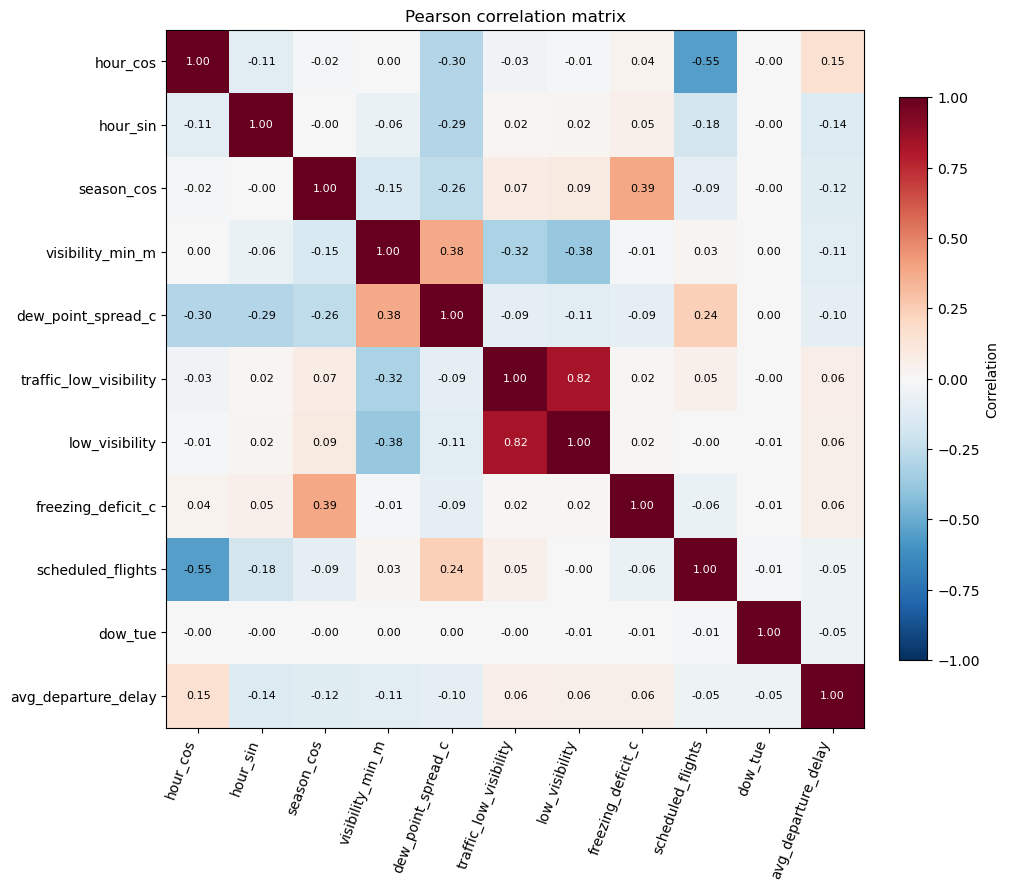

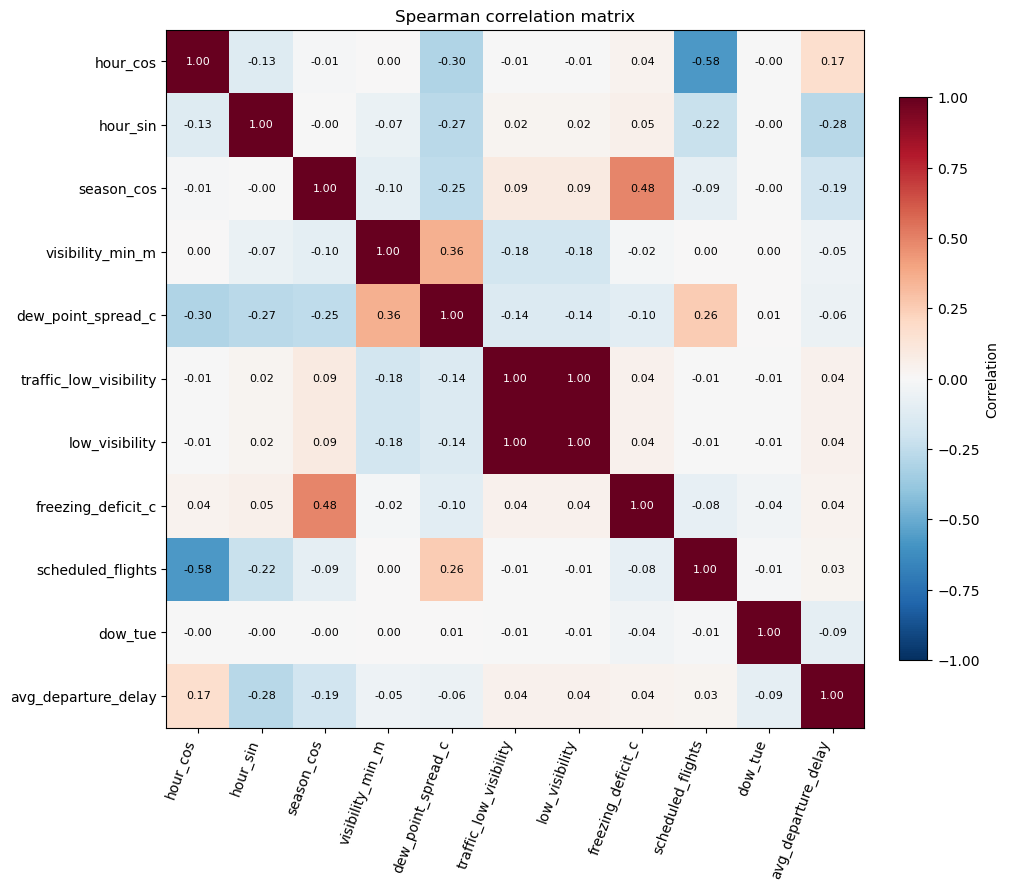

In [33]:
# setting up correlation data
numeric = feature_df.drop(columns='hour_local')
candidates = numeric.columns.drop(target)
relationships = pd.DataFrame({
    'pearson': numeric.corr(method='pearson', min_periods=30)[target].drop(target),
    'spearman': numeric.corr(method='spearman', min_periods=30)[target].drop(target),
    'paired_hours': {c: numeric[[c, target]].dropna().shape[0] for c in candidates},
})

# making correlations all positive and then sorting
relationships['abs_pearson'] = relationships['pearson'].abs()
relationships = relationships.sort_values('abs_pearson', ascending=False)
(relationships.drop(columns='abs_pearson').round(3)).to_csv('correlations.csv')
display(relationships.drop(columns='abs_pearson').round(3))

# core matrix uses the same complete-case rows for every entry.
top_core = (
    regression_df[core_features + [target]]
    .corr()[target]
    .drop(target)
    .abs()
    .nlargest(10)
    .index.tolist()
)

for method in ['pearson', 'spearman']:
    matrix = regression_df[top_core + [target]].corr(method=method)

    # Create a separate figure for each correlation method
    fig, ax = plt.subplots(figsize=(10, 9), constrained_layout=True)
    im = ax.imshow(matrix, cmap='RdBu_r', vmin=-1, vmax=1)

    ax.set_xticks(range(len(matrix)), matrix.columns, rotation=70, ha='right')
    ax.set_yticks(range(len(matrix)), matrix.index)
    ax.set_title(f'{method.title()} correlation matrix')

    # Write correlation values inside the squares
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value = matrix.iloc[i, j]
            ax.text(
                j, i, f'{value:.2f}',
                ha='center', va='center', fontsize=8,
                color='white' if abs(value) > 0.65 else 'black'
            )

    fig.colorbar(im, ax=ax, shrink=0.75, label='Correlation')
    fig.savefig(f'{method}_correlation_matrix.png', dpi=300, bbox_inches='tight')

### Preliminary scatterplots
Show traffic, weather, an engineered saturation feature, and the strongest nonbinary candidate. Use all available pairs, preserve outliers, and overlay quantile-bin means to make patterns visible despite overplotting. The orange line is descriptive, not a fitted regression.

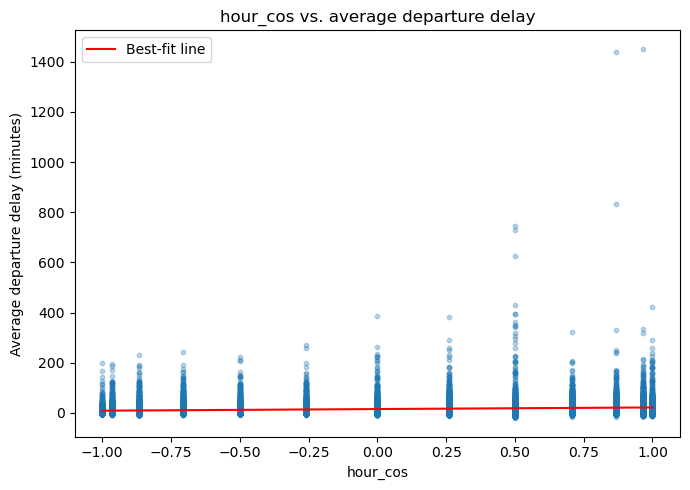

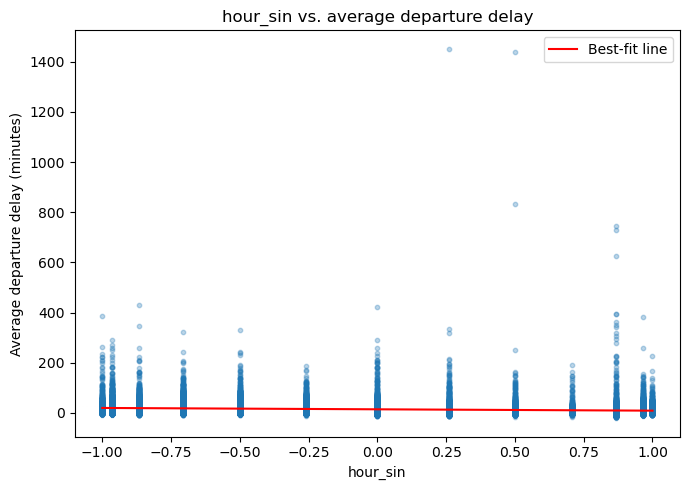

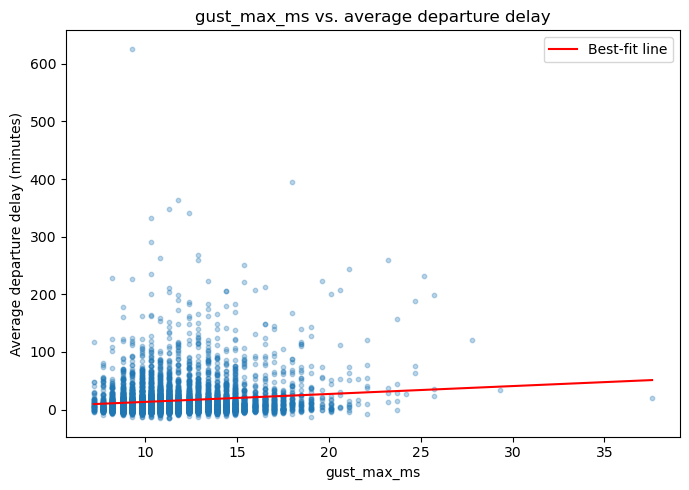

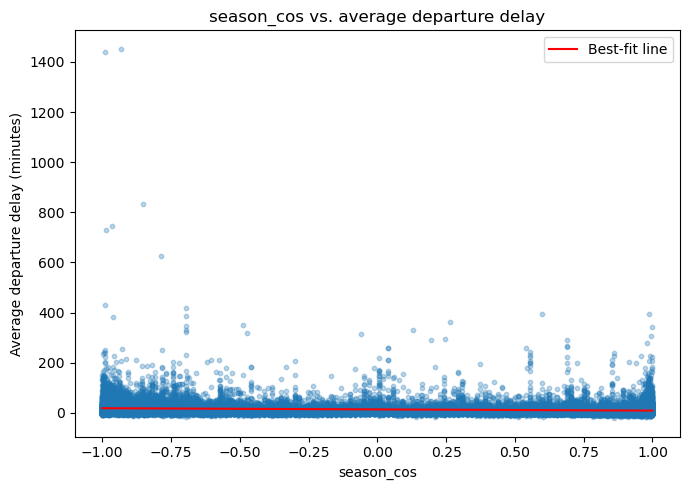

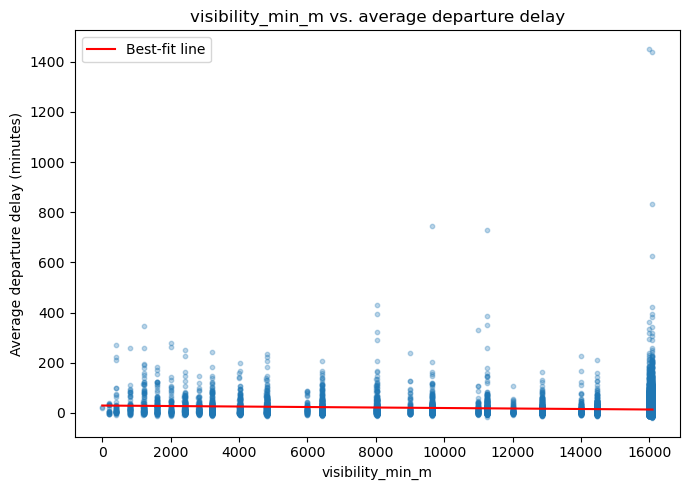

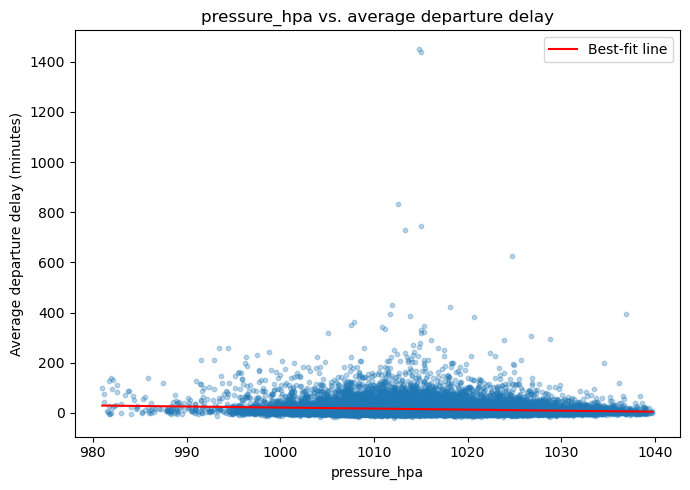

In [35]:
plot_features = relationships['pearson'].abs().nlargest(6).index

for col in plot_features:
    pairs = feature_df[[col, target]].dropna()
    x = pairs[col]
    y = pairs[target]

    # Calculate the slope and intercept of the best-fit line
    slope, intercept = np.polyfit(x, y, 1)
    line_x = np.linspace(x.min(), x.max(), 100)

    plt.figure(figsize=(7, 5))
    plt.scatter(x, y, s=10, alpha=0.3)
    plt.plot(line_x, slope * line_x + intercept, color='red', label='Best-fit line')
    plt.xlabel(col)
    plt.ylabel('Average departure delay (minutes)')
    plt.title(f'{col} vs. average departure delay')
    plt.legend()
    plt.tight_layout()
    plt.show()

## Save the prepared data for Week 6

In [ ]:
regression_df.to_csv("regression_data.csv", index=False)